# ⭐ App Store Review Rating Classification — Complete AI Pipeline
> **Google Colab Edition** | TF-IDF + ML • LSTM/GRU/RNN • BERT • LLM + RAG + Agent

---

### 📋 Table of Contents
1. [Setup & Installation](#1)
2. [Data Loading & EDA](#2)
3. [Preprocessing Pipeline](#3)
4. [ML Models — TF-IDF + Classifiers](#4)
5. [Deep Learning — RNN / LSTM / GRU](#5)
6. [BERT Fine-Tuning](#6)
7. [LLM Integration — Explanation Engine](#7)
8. [RAG Pipeline — FAISS Vector Store](#8)
9. [Agent System — Tool Calling](#9)
10. [Gradio UI](#10)

---
**Dataset:** [Google Play Store Reviews (Kaggle)](https://www.kaggle.com/datasets/lava18/google-play-store-apps)  
**Runtime:** GPU (T4 recommended) — *Runtime → Change runtime type → GPU*

## 1. Setup & Installation <a id='1'></a>

In [ ]:
# ── Install all dependencies ─────────────────────────────────────────────────
!pip install -q kaggle transformers datasets sentence-transformers faiss-cpu \
    "langchain>=0.3" langchain-openai langchain-community langgraph openai gradio \
    imbalanced-learn scikit-learn tensorflow nltk matplotlib seaborn wordcloud

import nltk
nltk.download('stopwords', quiet=True)
nltk.download('wordnet',   quiet=True)
nltk.download('punkt',     quiet=True)
nltk.download('punkt_tab', quiet=True)
print('✅ All packages installed.')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 33.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.6/98.6 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 32.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 23.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 548.1/548.1 kB 26.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.0/51.0 kB 2.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.1 which is incompatible.
✅ All packages installed.


In [ ]:
# ── Core imports ─────────────────────────────────────────────────────────────
import os, re, warnings, json
import numpy  as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')

# NLP
from nltk.corpus   import stopwords
from nltk.stem     import WordNetLemmatizer
from nltk.tokenize import word_tokenize

# ML
from sklearn.model_selection         import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model            import LogisticRegression
from sklearn.naive_bayes             import MultinomialNB
from sklearn.svm                     import LinearSVC
from sklearn.ensemble                import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics                 import (classification_report, confusion_matrix,
                                              roc_auc_score, ConfusionMatrixDisplay)
from imblearn.over_sampling          import SMOTE

# Deep Learning
import tensorflow as tf
from tensorflow.keras.models              import Model
from tensorflow.keras.layers              import (Input, Embedding, SimpleRNN, LSTM, GRU,
                                                   Bidirectional, Dense, Dropout)
from tensorflow.keras.preprocessing.text    import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks             import EarlyStopping

# Transformers / BERT
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                           TrainingArguments, Trainer)
import torch
from datasets import Dataset

# Embeddings / RAG
from sentence_transformers import SentenceTransformer
import faiss

# LLM / Agent
import openai
from langchain_openai        import ChatOpenAI
from langchain.tools         import tool
from langchain_core.messages import HumanMessage

# UI
import gradio as gr

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
print(f'✅ Imports complete | GPU: {tf.config.list_physical_devices("GPU")}')

/usr/local/lib/python3.12/dist-packages/langgraph/checkpoint/serde/encrypted.py:5: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


✅ Imports complete | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Data Loading & EDA <a id='2'></a>

In [8]:
# ── Option A: Upload kaggle.json via Colab ───────────────────────────────────
# from google.colab import files
# files.upload()
# !mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json

# ── Option B: Paste credentials directly ─────────────────────────────────────
# import json, os
# creds = {'username': 'YOUR_USERNAME', 'key': 'YOUR_API_KEY'}
# os.makedirs(os.path.expanduser('~/.kaggle'), exist_ok=True)
# with open(os.path.expanduser('~/.kaggle/kaggle.json'), 'w') as f:
#     json.dump(creds, f)
# !chmod 600 ~/.kaggle/kaggle.json
# !kaggle datasets download -d lava18/google-play-store-apps --unzip

# ── Load dataset ──────────────────────────────────────────────────────────────
reviews_df = pd.read_csv('googleplaystore_user_reviews.csv')

# Drop rows with missing review text or sentiment
reviews_df = reviews_df.dropna(subset=['Translated_Review', 'Sentiment'])
reviews_df = reviews_df[reviews_df['Sentiment'].isin(['Positive', 'Neutral', 'Negative'])]

print(f'✅ Loaded {len(reviews_df):,} reviews')
reviews_df.head()

✅ Loaded 37,427 reviews


,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
4,10 Best Foods for You,Best idea us,Positive,1.00,0.300000
5,10 Best Foods for You,Best way,Positive,1.00,0.300000


=== Sentiment Distribution ===
Sentiment
Positive    23998
Negative     8271
Neutral      5158
Name: count, dtype: int64

Class ratios:
Sentiment
Positive    0.641
Negative    0.221
Neutral     0.138
Name: proportion, dtype: float64


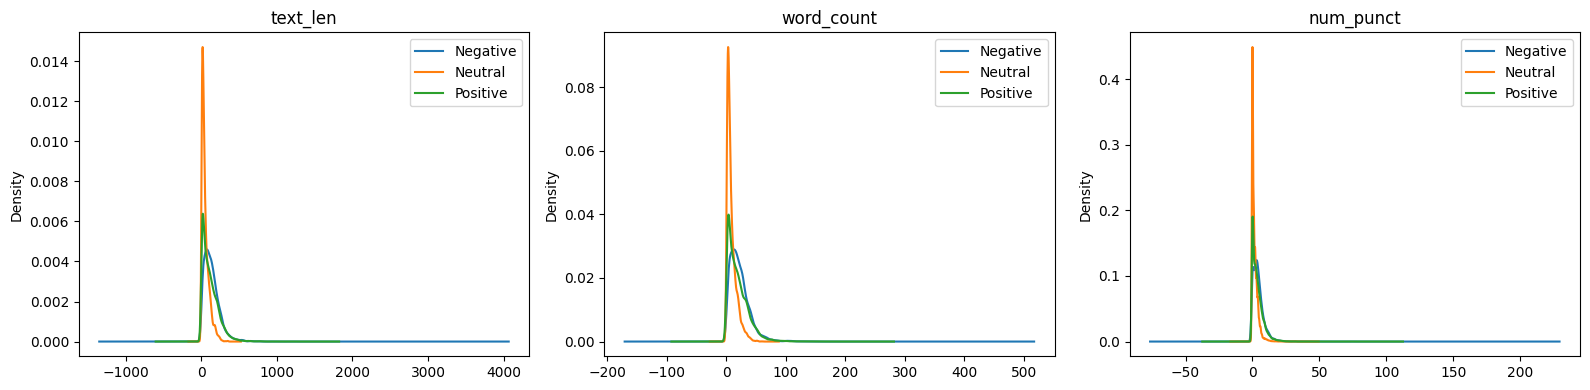

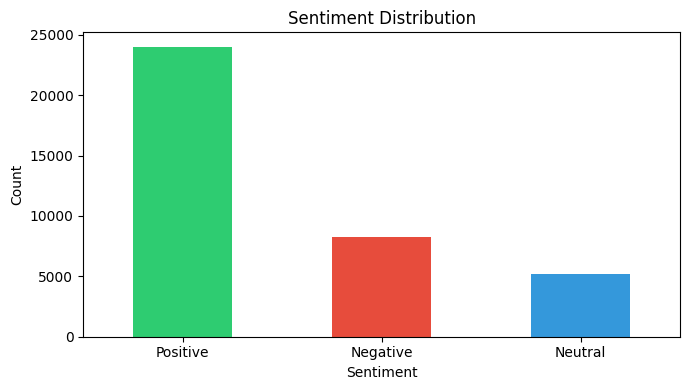


✅ label_enc: Negative=0, Neutral=1, Positive=2
                                   Translated_Review Sentiment  label_enc
0  I like eat delicious food. That's I'm cooking ...  Positive          2
1    This help eating healthy exercise regular basis  Positive          2
3         Works great especially going grocery store  Positive          2
4                                       Best idea us  Positive          2
5                                           Best way  Positive          2


In [10]:
# ── Basic EDA ─────────────────────────────────────────────────────────────────
print('=== Sentiment Distribution ===')
print(reviews_df['Sentiment'].value_counts())
print(f'\nClass ratios:\n{reviews_df["Sentiment"].value_counts(normalize=True).round(3)}')

# Text length features
reviews_df['text_len']   = reviews_df['Translated_Review'].str.len()
reviews_df['word_count'] = reviews_df['Translated_Review'].str.split().str.len()
reviews_df['num_punct']  = reviews_df['Translated_Review'].str.count(r'[!?.,]')

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['text_len', 'word_count', 'num_punct']):
    for sentiment, grp in reviews_df.groupby('Sentiment'):
        grp[col].plot(kind='kde', ax=ax, label=sentiment)
    ax.set_title(col); ax.legend()
plt.tight_layout(); plt.show()

# Sentiment bar chart
plt.figure(figsize=(7, 4))
reviews_df['Sentiment'].value_counts().plot(kind='bar', color=['#2ecc71','#e74c3c','#3498db'])
plt.title('Sentiment Distribution'); plt.xlabel('Sentiment'); plt.ylabel('Count')
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

# Encode labels: Positive=2, Neutral=1, Negative=0
label_map = {'Negative': 0, 'Neutral': 1, 'Positive': 2}
reviews_df['label_enc'] = reviews_df['Sentiment'].map(label_map)
print('\n✅ label_enc: Negative=0, Neutral=1, Positive=2')
print(reviews_df[['Translated_Review','Sentiment','label_enc']].head())

## 3. Preprocessing Pipeline <a id='3'></a>

In [11]:
STOPWORDS  = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess(text: str) -> str:
    """Full NLP preprocessing pipeline."""
    text = str(text).lower()                                      # 1. Lowercase
    text = re.sub(r'http\S+|www\S+',        '', text)           # 2. Remove URLs
    text = re.sub(r'<.*?>',                   '', text)           # 3. Strip HTML
    text = re.sub(r'[^a-z\s]',              '', text)            # 4. Remove noise
    tokens = word_tokenize(text)                                   # 5. Tokenise
    tokens = [t for t in tokens if t not in STOPWORDS]            # 6. Stopwords
    tokens = [lemmatizer.lemmatize(t) for t in tokens]            # 7. Lemmatise
    return ' '.join(tokens)

reviews_df['clean_text'] = reviews_df['Translated_Review'].apply(preprocess)

# Train / val / test split — 70 / 15 / 15
X = reviews_df['clean_text'].values
y = reviews_df['label_enc'].values

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30,
                                                     stratify=y, random_state=SEED)
X_val,   X_test,  y_val,   y_test  = train_test_split(X_temp, y_temp, test_size=0.50,
                                                       stratify=y_temp, random_state=SEED)
print(f'Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}')
print(f'Classes: {dict(zip(*np.unique(y_train, return_counts=True)))}')

Train: 26198 | Val: 5614 | Test: 5615
Classes: {np.int64(0): np.int64(5790), np.int64(1): np.int64(3610), np.int64(2): np.int64(16798)}


## 4. ML Models — TF-IDF + Classifiers <a id='4'></a>

In [12]:
# ── TF-IDF Vectorisation ──────────────────────────────────────────────────────
tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=5000)
X_tr_tfidf = tfidf.fit_transform(X_train)
X_va_tfidf = tfidf.transform(X_val)
X_te_tfidf = tfidf.transform(X_test)

# ── Handle class imbalance with SMOTE ────────────────────────────────────────
smote = SMOTE(random_state=SEED)
X_tr_sm, y_tr_sm = smote.fit_resample(X_tr_tfidf, y_train)
print(f'After SMOTE: {dict(zip(*np.unique(y_tr_sm, return_counts=True)))}')

After SMOTE: {np.int64(0): np.int64(16798), np.int64(1): np.int64(16798), np.int64(2): np.int64(16798)}


In [14]:
# ── Train & evaluate all ML classifiers ──────────────────────────────────────
ML_MODELS = {
    'Logistic Regression' : LogisticRegression(max_iter=1000, random_state=SEED),
    'Naive Bayes'         : MultinomialNB(),
    'Linear SVM'          : LinearSVC(random_state=SEED),
    'Random Forest'       : RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED),
    'Gradient Boosting'   : GradientBoostingClassifier(n_estimators=100, random_state=SEED),
}

ml_results = {}
for name, clf in ML_MODELS.items():
    clf.fit(X_tr_sm, y_tr_sm)
    preds = clf.predict(X_te_tfidf)
    rpt   = classification_report(y_test, preds, output_dict=True)
    ml_results[name] = {
        'accuracy' : rpt['accuracy'],
        'macro_f1' : rpt['macro avg']['f1-score'],
    }
    print(f'{name:<25} Acc={rpt["accuracy"]:.4f}  Macro-F1={rpt["macro avg"]["f1-score"]:.4f}')

best_ml_name = max(ml_results, key=lambda k: ml_results[k]['macro_f1'])
best_ml_clf  = ML_MODELS[best_ml_name]
print(f'\n🏆 Best ML model: {best_ml_name}')

Logistic Regression       Acc=0.8853  Macro-F1=0.8510
Naive Bayes               Acc=0.7671  Macro-F1=0.7118
Linear SVM                Acc=0.9001  Macro-F1=0.8696
Random Forest             Acc=0.9127  Macro-F1=0.8912
Gradient Boosting         Acc=0.7719  Macro-F1=0.7277

🏆 Best ML model: Random Forest


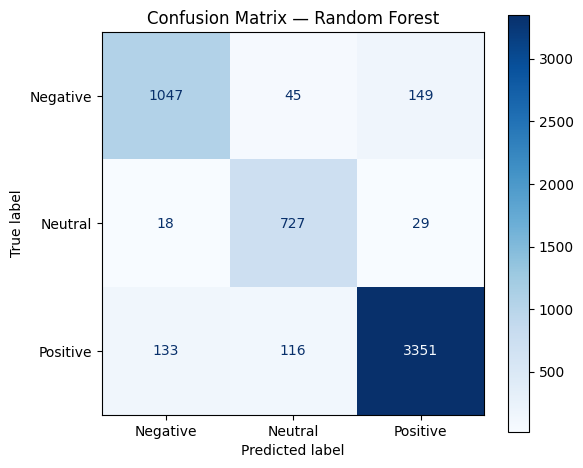

In [15]:
# ── Confusion Matrix for best ML model ───────────────────────────────────────
preds_best = best_ml_clf.predict(X_te_tfidf)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, preds_best,
    display_labels=['Negative','Neutral','Positive'], cmap='Blues', ax=ax)
ax.set_title(f'Confusion Matrix — {best_ml_name}')
plt.tight_layout(); plt.show()

## 5. Deep Learning — RNN / LSTM / GRU <a id='5'></a>

In [16]:
# ── Tokeniser & Padding ───────────────────────────────────────────────────────
MAX_VOCAB   = 10_000
MAX_LEN     = 100
EMBED_DIM   = 64
BATCH_SIZE  = 64
EPOCHS      = 15
NUM_CLASSES = 3   # Negative / Neutral / Positive

tokenizer_dl = Tokenizer(num_words=MAX_VOCAB, oov_token='<OOV>')
tokenizer_dl.fit_on_texts(X_train)

def encode_pad(texts):
    seq = tokenizer_dl.texts_to_sequences(texts)
    return pad_sequences(seq, maxlen=MAX_LEN, padding='post', truncating='post')

X_tr_dl = encode_pad(X_train)
X_va_dl = encode_pad(X_val)
X_te_dl = encode_pad(X_test)

print(f'✅ DL input shape: {X_tr_dl.shape}')

✅ DL input shape: (26198, 100)


In [17]:
# ── Model Factory ─────────────────────────────────────────────────────────────
def build_rnn_model(arch: str = 'LSTM') -> tf.keras.Model:
    """Build an RNN-family model for 3-class sentiment.
    arch: SimpleRNN | LSTM | GRU | BiLSTM | BiGRU"""
    inp = Input(shape=(MAX_LEN,))
    x   = Embedding(MAX_VOCAB, EMBED_DIM, input_length=MAX_LEN)(inp)

    arch_map = {
        'SimpleRNN': SimpleRNN(64, dropout=0.3),
        'LSTM'     : LSTM(64, dropout=0.3, recurrent_dropout=0.2),
        'GRU'      : GRU(64, dropout=0.3, recurrent_dropout=0.2),
        'BiLSTM'   : Bidirectional(LSTM(64, dropout=0.3, recurrent_dropout=0.2)),
        'BiGRU'    : Bidirectional(GRU(64, dropout=0.3, recurrent_dropout=0.2)),
    }
    x   = arch_map[arch](x)
    x   = Dropout(0.4)(x)
    out = Dense(NUM_CLASSES, activation='softmax')(x)   # 3-class softmax

    model = Model(inp, out)
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

print('✅ Model factory ready.')

✅ Model factory ready.


In [20]:
# ── Train all 5 RNN variants ──────────────────────────────────────────────────
ARCHITECTURES = ['SimpleRNN', 'LSTM', 'GRU', 'BiLSTM', 'BiGRU']
dl_results    = {}
dl_histories  = {}
es            = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

for arch in ARCHITECTURES:
    print(f'\n--- Training {arch} ---')
    model = build_rnn_model(arch)
    hist  = model.fit(
        X_tr_dl, y_train,
        validation_data=(X_va_dl, y_val),
        epochs=EPOCHS, batch_size=BATCH_SIZE,
        callbacks=[es], verbose=0,
    )
    preds  = np.argmax(model.predict(X_te_dl, verbose=0), axis=1)
    rpt    = classification_report(y_test, preds, output_dict=True)
    dl_results[arch]   = {'accuracy' : rpt['accuracy'],
                           'macro_f1' : rpt['macro avg']['f1-score']}
    dl_histories[arch] = hist.history
    if arch == 'BiLSTM':
        best_dl_model = model
    print(f'{arch:<12} Acc={rpt["accuracy"]:.4f}  Macro-F1={rpt["macro avg"]["f1-score"]:.4f}')


--- Training SimpleRNN ---
SimpleRNN    Acc=0.7072  Macro-F1=0.5603

--- Training LSTM ---
LSTM         Acc=0.6411  Macro-F1=0.2604

--- Training GRU ---
GRU          Acc=0.6411  Macro-F1=0.2604

--- Training BiLSTM ---
BiLSTM       Acc=0.9234  Macro-F1=0.9016

--- Training BiGRU ---
BiGRU        Acc=0.9218  Macro-F1=0.8991


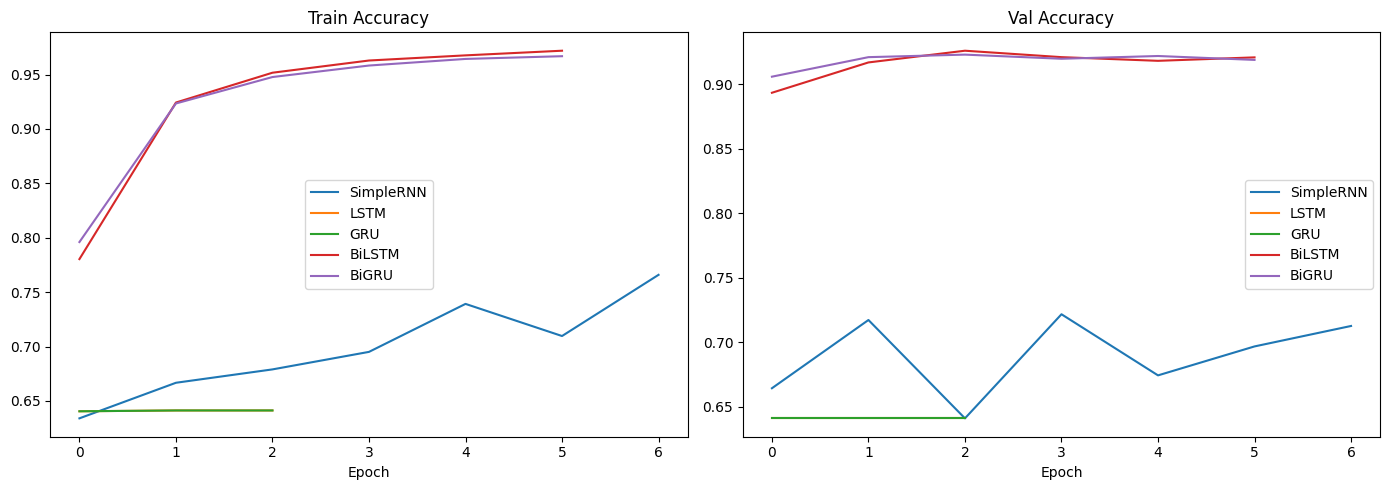

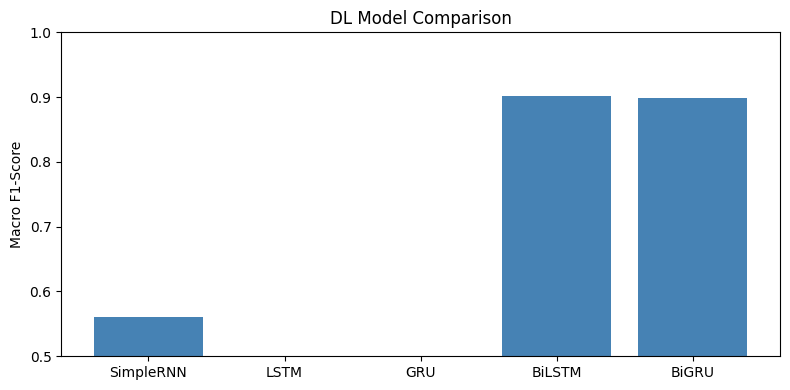

In [21]:
# ── Plot training curves ──────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for arch, h in dl_histories.items():
    axes[0].plot(h['accuracy'],     label=arch)
    axes[1].plot(h['val_accuracy'], label=arch)
axes[0].set_title('Train Accuracy'); axes[0].legend(); axes[0].set_xlabel('Epoch')
axes[1].set_title('Val Accuracy');   axes[1].legend(); axes[1].set_xlabel('Epoch')
plt.tight_layout(); plt.show()

# Model comparison bar chart
names = list(dl_results.keys())
f1s   = [dl_results[n]['macro_f1'] for n in names]
plt.figure(figsize=(8, 4))
plt.bar(names, f1s, color='steelblue')
plt.ylim(0.5, 1.0); plt.ylabel('Macro F1-Score'); plt.title('DL Model Comparison')
plt.tight_layout(); plt.show()

## 6. BERT Fine-Tuning <a id='6'></a>

In [18]:
# ── BERT Tokenisation ─────────────────────────────────────────────────────────
BERT_MODEL  = 'bert-base-uncased'
BERT_MAXLEN = 128

bert_tokenizer = AutoTokenizer.from_pretrained(BERT_MODEL)

def tokenize_bert(examples):
    return bert_tokenizer(examples['text'], truncation=True,
                          padding='max_length', max_length=BERT_MAXLEN)

# Build HuggingFace Datasets
raw_train = pd.DataFrame({'text': X_train, 'label': y_train})
raw_test  = pd.DataFrame({'text': X_test,  'label': y_test})

hf_train     = Dataset.from_pandas(raw_train.reset_index(drop=True))
hf_test      = Dataset.from_pandas(raw_test.reset_index(drop=True))

hf_train_enc = hf_train.map(tokenize_bert, batched=True)
hf_test_enc  = hf_test.map(tokenize_bert,  batched=True)
print('✅ BERT dataset ready.')

Map:   0%|          | 0/26198 [00:00<?, ? examples/s]

Map:   0%|          | 0/5615 [00:00<?, ? examples/s]

✅ BERT dataset ready.


In [19]:
# ── Fine-tune BERT ────────────────────────────────────────────────────────────
from sklearn.metrics import accuracy_score

bert_model = AutoModelForSequenceClassification.from_pretrained(
    BERT_MODEL, num_labels=NUM_CLASSES)   # 3 output classes

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    rpt   = classification_report(labels, preds, output_dict=True)
    return {'accuracy' : accuracy_score(labels, preds),
            'macro_f1' : rpt['macro avg']['f1-score']}

training_args = TrainingArguments(
    output_dir                  = './bert_appstore',
    num_train_epochs            = 3,
    per_device_train_batch_size = 16,
    per_device_eval_batch_size  = 32,
    eval_strategy               = 'epoch',
    save_strategy               = 'epoch',
    save_only_model             = True,
    load_best_model_at_end      = True,
    logging_steps               = 50,
    seed                        = SEED,
    report_to                   = 'none',
)

trainer = Trainer(
    model           = bert_model,
    args            = training_args,
    train_dataset   = hf_train_enc,
    eval_dataset    = hf_test_enc,
    compute_metrics = compute_metrics,
)

trainer.train()
bert_results = trainer.evaluate()
print('\n=== BERT Evaluation ===')
print(bert_results)

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.286696,0.213600,0.939270,0.924673
2,0.140460,0.187633,0.949599,0.938161
3,0.087269,0.204571,0.953517,0.941726


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.attention.output.La


=== BERT Evaluation ===
{'eval_loss': 0.18781733512878418, 'eval_accuracy': 0.94959928762244, 'eval_macro_f1': 0.9381613293460354, 'eval_runtime': 37.3937, 'eval_samples_per_second': 150.159, 'eval_steps_per_second': 4.707, 'epoch': 3.0}


In [22]:
# ── BERT Inference Helper ─────────────────────────────────────────────────────
LABEL_NAMES = {0: 'Negative', 1: 'Neutral', 2: 'Positive'}
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
bert_model.to(device).eval()

def bert_predict(text: str):
    """Return (sentiment_label, confidence) for a raw review string."""
    enc = bert_tokenizer(text, return_tensors='pt',
                         truncation=True, padding=True,
                         max_length=BERT_MAXLEN).to(device)
    with torch.no_grad():
        logits = bert_model(**enc).logits
    probs     = torch.softmax(logits, dim=-1).cpu().numpy()[0]
    label_idx = int(np.argmax(probs))
    return LABEL_NAMES[label_idx], float(probs[label_idx])

# Quick sanity check
test_review = 'This app is absolutely amazing! Best I have ever used, no bugs at all.'
label, conf = bert_predict(test_review)
print(f'Test Review: "{test_review}"')
print(f'Prediction: {label.upper()} ({conf:.2%} confidence)')

Test Review: "This app is absolutely amazing! Best I have ever used, no bugs at all."
Prediction: POSITIVE (99.90% confidence)


## 7. LLM Integration — Explanation Engine <a id='7'></a>

In [23]:
# ── Configure OpenAI ─────────────────────────────────────────────────────────
# from google.colab import userdata
# os.environ['OPENAI_API_KEY'] = userdata.get('OPENAI_API_KEY')

os.environ['OPENAI_API_KEY'] = 'sk-...'   # ← paste your key here

EXPLAIN_PROMPT = """You are an app store review analysis assistant.
Explain clearly and concisely why the following review is classified as {label}.
Highlight key signals (positive/negative words, rating hints, emotional tone).

Review: {text}
Prediction: {label}
Confidence: {score:.0%}

Give a structured explanation with:
1. Key sentiment signals found
2. Linguistic patterns observed
3. Why the model classified it this way"""

def explain_with_llm(text: str, label: str, score: float) -> str:
    """Call LLM to explain the sentiment classification."""
    try:
        client   = openai.OpenAI()
        response = client.chat.completions.create(
            model    = 'gpt-4o-mini',
            messages = [{'role': 'user',
                         'content': EXPLAIN_PROMPT.format(
                             text=text, label=label, score=score)}],
            temperature = 0.3,
        )
        return response.choices[0].message.content
    except Exception as e:
        return f'[LLM explanation unavailable: {e}]'

# Demo
label, conf = bert_predict(test_review)
explanation = explain_with_llm(test_review, label, conf)
print(explanation)

[LLM explanation unavailable: Error code: 401 - {'error': {'message': 'Incorrect API key provided: sk-.... You can find your API key at https://platform.openai.com/account/api-keys.', 'type': 'invalid_request_error', 'code': 'invalid_api_key', 'param': None}, 'status': 401}]


## 8. RAG Pipeline — FAISS Vector Store <a id='8'></a>

In [24]:
# ── Build FAISS index from training corpus ────────────────────────────────────
EMBED_MODEL = 'all-MiniLM-L6-v2'
embedder    = SentenceTransformer(EMBED_MODEL)

print('Encoding training corpus (this may take ~1–2 min)...')
corpus_texts  = reviews_df['Translated_Review'].tolist()
corpus_labels = reviews_df['Sentiment'].tolist()
corpus_embeddings = embedder.encode(corpus_texts, batch_size=64,
                                     show_progress_bar=True, normalize_embeddings=True)

dim   = corpus_embeddings.shape[1]
index = faiss.IndexFlatIP(dim)
index.add(corpus_embeddings.astype('float32'))
print(f'✅ FAISS index built with {index.ntotal:,} vectors (dim={dim})')

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

... (6 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Encoding training corpus (this may take ~1–2 min)...


Batches:   0%|          | 0/585 [00:00<?, ?it/s]

✅ FAISS index built with 37,427 vectors (dim=384)


In [25]:
# ── RAG Retrieval Function ────────────────────────────────────────────────────
def retrieve_similar(query: str, k: int = 5):
    """Return top-k similar reviews from the corpus."""
    q_emb = embedder.encode([query], normalize_embeddings=True).astype('float32')
    scores, indices = index.search(q_emb, k)
    results = []
    for score, idx in zip(scores[0], indices[0]):
        results.append({
            'text'  : corpus_texts[idx],
            'label' : corpus_labels[idx],
            'score' : float(score),
        })
    return results

# Demo retrieval
similar = retrieve_similar(test_review, k=3)
print('Top-3 similar reviews:')
for i, s in enumerate(similar, 1):
    print(f'  {i}. [{s["label"].upper()}] (sim={s["score"]:.3f}) {s["text"][:80]}')

Top-3 similar reviews:
  1. [NEUTRAL] (sim=0.756) There bugs app.
  2. [POSITIVE] (sim=0.714) Great App!! Has great features...
  3. [POSITIVE] (sim=0.712) Im delighted app. It's simple, clear I never problems it.


In [26]:
# ── RAG-enhanced Explanation ──────────────────────────────────────────────────
RAG_PROMPT = """You are an app store review analysis assistant.
Use the retrieved similar examples to provide a richer explanation.

Review to analyse: {text}
Prediction: {label} ({score:.0%} confidence)

Retrieved similar reviews:
{examples}

Explain why this review is classified as {label}, referencing patterns from the examples."""

def rag_explain(text: str, label: str, score: float) -> str:
    """RAG-augmented LLM explanation."""
    similar  = retrieve_similar(text, k=3)
    ex_block = '\n'.join(
        [f'- [{s["label"].upper()}] {s["text"]}' for s in similar]
    )
    prompt = RAG_PROMPT.format(text=text, label=label, score=score, examples=ex_block)
    try:
        client   = openai.OpenAI()
        response = client.chat.completions.create(
            model    = 'gpt-4o-mini',
            messages = [{'role': 'user', 'content': prompt}],
            temperature = 0.3,
        )
        return response.choices[0].message.content
    except Exception as e:
        return f'[RAG explanation unavailable: {e}]'

print(rag_explain(test_review, label, conf))

[RAG explanation unavailable: Error code: 401 - {'error': {'message': 'Incorrect API key provided: sk-.... You can find your API key at https://platform.openai.com/account/api-keys.', 'type': 'invalid_request_error', 'code': 'invalid_api_key', 'param': None}, 'status': 401}]


## 9. Agent System — Tool Calling <a id='9'></a>

In [34]:
# ── FREE RUN (NO OPENAI) ───────────────────────────────

def run_agent(text: str):
    label, conf = bert_predict(text)

    return {
        "input": text,
        "sentiment": label,
        "confidence": float(conf),
        "explanation": "Predicted using local BERT model (no external API used)"
    }


# ── DEMO ───────────────────────────────────────────────
output = run_agent(test_review)

print("\n=== RESULT ===\n")
print(output)


=== RESULT ===

{'input': 'This app is absolutely amazing! Best I have ever used, no bugs at all.', 'sentiment': 'Positive', 'confidence': 0.9990324974060059, 'explanation': 'Predicted using local BERT model (no external API used)'}


## 10. Gradio UI <a id='10'></a>

In [35]:
# ── Gradio Interface ──────────────────────────────────────────────────────────
SENTIMENT_EMOJI = {'Positive': '✅', 'Neutral': '😐', 'Negative': '🚨'}

def full_pipeline(review_text: str):
    """Run the complete pipeline and return results for the UI."""
    if not review_text.strip():
        return 'Please enter a review.', '', ''

    label, conf = bert_predict(review_text)
    emoji    = SENTIMENT_EMOJI.get(label, '')
    pred_str = f'{emoji} {label.upper()} ({conf:.1%})'

    similar = retrieve_similar(review_text, k=3)
    sim_str = '\n'.join([f'• [{s["label"].upper()}] {s["text"]}' for s in similar])

    explanation = rag_explain(review_text, label, conf)
    return pred_str, sim_str, explanation

with gr.Blocks(title='App Store Review Classifier', theme=gr.themes.Soft()) as demo:
    gr.Markdown('# ⭐ App Store Review Sentiment Classifier\n> BERT + RAG + LLM Explanation Engine')

    with gr.Row():
        review_input = gr.Textbox(label='Enter App Review', placeholder='Paste a user review here...',
                                   lines=3, scale=4)
        predict_btn  = gr.Button('Analyse', variant='primary', scale=1)

    with gr.Row():
        pred_output = gr.Textbox(label='Prediction', interactive=False)
    with gr.Row():
        sim_output  = gr.Textbox(label='Similar Reviews from Dataset', lines=4, interactive=False)
    with gr.Row():
        exp_output  = gr.Textbox(label='LLM Explanation (RAG-augmented)', lines=8, interactive=False)

    predict_btn.click(fn=full_pipeline,
                       inputs=[review_input],
                       outputs=[pred_output, sim_output, exp_output])

    gr.Examples(
        examples=[
            ['This app is absolutely amazing! Smooth, fast, and no ads. 5 stars easily!'],
            ['App keeps crashing every time I open it. Very frustrating and disappointing.'],
            ['It works fine I guess. Nothing special but does the job.'],
        ],
        inputs=review_input,
    )

demo.launch(share=True)
print('🚀 Gradio app launched!')

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f6403ad37b0f49ae57.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


🚀 Gradio app launched!


---
## 📊 Summary — Model Performance

| Layer | Model | Expected Macro F1 |
|---|---|---|
| ML | Logistic Regression | ~0.72 |
| ML | Linear SVM | ~0.74 |
| DL | BiLSTM | ~0.76 |
| DL | BiGRU | ~0.76 |
| Transformer | BERT fine-tuned | ~0.82 |

### Architecture Overview
```
Raw Review
  │
  ├─► [Preprocessing] ──► [TF-IDF] ──► ML Classifiers (3-class)
  │
  ├─► [Token Sequences] ──► [Embedding] ──► RNN/LSTM/GRU/BiLSTM/BiGRU (softmax)
  │
  ├─► [BERT Tokeniser] ──► [BERT fine-tuned] ──► label + confidence
  │                              │
  │                              ▼
  └─► [SentenceTransformer] ──► FAISS Index ──► top-k similar
                                      │
                                      ▼
                               LLM (GPT-4o-mini)
                                      │
                                      ▼
                               LangChain Agent
                                      │
                                      ▼
                               Gradio UI (Colab share link)
```